# Feed Amount Analysis - Frame-Level Analysis

This notebook analyzes the feed amount per frame in a video, based on the bounding box area from YOLO detection.

Features:
- Read video and run inference frame-by-frame
- Calculate total feed bounding box area per frame
- Apply Kalman Filter for noise reduction
- Predict feed area for the next frame
- Visualize curves before and after filtering

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from ultralytics import YOLO
from scipy.ndimage import uniform_filter1d
import warnings
warnings.filterwarnings('ignore')

# Set default font
plt.rcParams['font.sans-serif'] = ['DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

## 1. Kalman Filter Implementation

In [2]:
class KalmanFilterND:
    """
    1D Kalman Filter 用於時間序列過濾
    """
    def __init__(self, process_variance, measurement_variance, initial_value=0, initial_estimate_error=1):
        """
        Args:
            process_variance: 過程噪聲方差 (Q)
            measurement_variance: 測量噪聲方差 (R)
            initial_value: 初始狀態值
            initial_estimate_error: 初始估計誤差 (P)
        """
        self.process_variance = process_variance
        self.measurement_variance = measurement_variance
        self.x = initial_value  # 狀態估計
        self.p = initial_estimate_error  # 估計誤差
        self.prediction = initial_value
    
    def update(self, measurement):
        """
        使用新測量值更新濾波器
        
        Args:
            measurement: 新的測量值
        
        Returns:
            filtered_value: 濾波後的值
        """
        # 預測步驟
        self.prediction = self.x
        self.p = self.p + self.process_variance
        
        # 更新步驟
        kalman_gain = self.p / (self.p + self.measurement_variance)
        self.x = self.x + kalman_gain * (measurement - self.x)
        self.p = (1 - kalman_gain) * self.p
        
        return self.x
    
    def predict_next(self):
        """
        預測下一個時間步的狀態
        
        Returns:
            predicted_value: 預測值
        """
        return self.x

## 2. Configuration Parameters

In [3]:
# Adjustable parameters
CONFIG = {
    'video_path': 'data/fish_feeding.mp4',
    'model_path': 'runs/train/fold-4_20260517_1930/weights/best.pt',
    'confidence_threshold': 0.40,  # 可調整的信心度閾值
    'device': 'cuda',  # 使用 GPU
    'kalman_q': 1.0,  # Kalman Filter 過程噪聲 (越大越跟隨測量值)
    'kalman_r': 10.0,  # Kalman Filter 測量噪聲 (越大越相信估計值)
    'max_frames': None,  # None 表示處理全部幀，設定數字則限制幀數
}

print("Configuration parameters:")
for k, v in CONFIG.items():
    print(f"  {k}: {v}")

Configuration parameters:
  video_path: data/fish_feeding.mp4
  model_path: runs/train/fold-4_20260517_1930/weights/best.pt
  confidence_threshold: 0.4
  device: cuda
  kalman_q: 1.0
  kalman_r: 10.0
  max_frames: None


## 3. Load Model and Video

In [4]:
# 加載 YOLO 模型
print(f"加載模型: {CONFIG['model_path']}")
model = YOLO(CONFIG['model_path'])
model.to(CONFIG['device'])

# 打開視頻
video_path = CONFIG['video_path']
print(f"\n加載視頻: {video_path}")
cap = cv2.VideoCapture(video_path)

if not cap.isOpened():
    raise ValueError(f"無法打開視頻: {video_path}")

# 取得視頻信息
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

print(f"視頻信息:")
print(f"  總幀數: {total_frames}")
print(f"  FPS: {fps}")
print(f"  解像度: {width}x{height}")
print(f"  總時長: {total_frames/fps:.2f}秒")

加載模型: runs/train/fold-4_20260517_1930/weights/best.pt

加載視頻: data/fish_feeding.mp4
視頻信息:
  總幀數: 563
  FPS: 30.0
  解像度: 1920x1080
  總時長: 18.77秒


## 4. Run Inference and Calculate Feed Area

In [5]:
# 初始化數據存儲
frame_numbers = []
feed_areas_raw = []  # 原始測量值
feed_areas_filtered = []  # Kalman 濾波後的值
predictions = []  # 預測值

# 初始化 Kalman Filter
kf = KalmanFilterND(
    process_variance=CONFIG['kalman_q'],
    measurement_variance=CONFIG['kalman_r'],
    initial_value=0
)

frame_idx = 0
max_frames = CONFIG['max_frames'] or total_frames

print(f"開始推論，共 {min(max_frames, total_frames)} 幀...")
print(f"信心度閾值: {CONFIG['confidence_threshold']}")
print()

開始推論，共 563 幀...
信心度閾值: 0.4



In [6]:
# 逐幀處理
import sys

while frame_idx < max_frames:
    ret, frame = cap.read()
    
    if not ret:
        print(f"\n到達視頻末尾在 Frame {frame_idx}")
        break
    
    # 進行 YOLO 推論
    results = model(frame, conf=CONFIG['confidence_threshold'], verbose=False)
    
    # 計算此幀的飼料面積
    frame_feed_area = 0
    
    if len(results) > 0:
        result = results[0]
        if result.boxes is not None and len(result.boxes) > 0:
            boxes = result.boxes
            # 計算所有 bounding box 的面積
            for box in boxes:
                # 取得 bounding box 坐標
                x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()
                width_box = x2 - x1
                height_box = y2 - y1
                area = width_box * height_box
                frame_feed_area += area
    
    # 儲存原始值
    frame_numbers.append(frame_idx)
    feed_areas_raw.append(frame_feed_area)
    
    # 使用 Kalman Filter 進行濾波
    filtered_value = kf.update(frame_feed_area)
    feed_areas_filtered.append(filtered_value)
    
    # 記錄預測值
    predictions.append(kf.predict_next())
    
    # 定期輸出進度
    if (frame_idx + 1) % 100 == 0:
        sys.stdout.write(f"\r已處理: {frame_idx + 1}/{min(max_frames, total_frames)} 幀")
        sys.stdout.flush()
    
    frame_idx += 1

cap.release()
print(f"\n\n推論完成！共處理 {len(frame_numbers)} 幀")

已處理: 500/563 幀

推論完成！共處理 563 幀


## 5. Data Statistics

In [7]:
# 轉換為 numpy 數組便於計算
feed_areas_raw = np.array(feed_areas_raw)
feed_areas_filtered = np.array(feed_areas_filtered)
predictions = np.array(predictions)

print("=" * 60)
print("飼料面積統計")
print("=" * 60)

print("\n原始值 (未濾波):")
print(f"  最小值: {feed_areas_raw.min():,.0f} pixels²")
print(f"  最大值: {feed_areas_raw.max():,.0f} pixels²")
print(f"  平均值: {feed_areas_raw.mean():,.0f} pixels²")
print(f"  標準差: {feed_areas_raw.std():,.0f} pixels²")

print("\nKalman 濾波後:")
print(f"  最小值: {feed_areas_filtered.min():,.0f} pixels²")
print(f"  最大值: {feed_areas_filtered.max():,.0f} pixels²")
print(f"  平均值: {feed_areas_filtered.mean():,.0f} pixels²")
print(f"  標準差: {feed_areas_filtered.std():,.0f} pixels²")

# 計算降噪效果
noise_reduction = (1 - (feed_areas_filtered.std() / feed_areas_raw.std())) * 100 if feed_areas_raw.std() > 0 else 0
print(f"\n降噪效果: {noise_reduction:.1f}% (標準差降低)")

飼料面積統計

原始值 (未濾波):
  最小值: 0 pixels²
  最大值: 2,032,343 pixels²
  平均值: 567,510 pixels²
  標準差: 366,654 pixels²

Kalman 濾波後:
  最小值: 56,931 pixels²
  最大值: 1,251,195 pixels²
  平均值: 563,833 pixels²
  標準差: 244,152 pixels²

降噪效果: 33.4% (標準差降低)


## 6. Visualization - Before/After Filtering Comparison

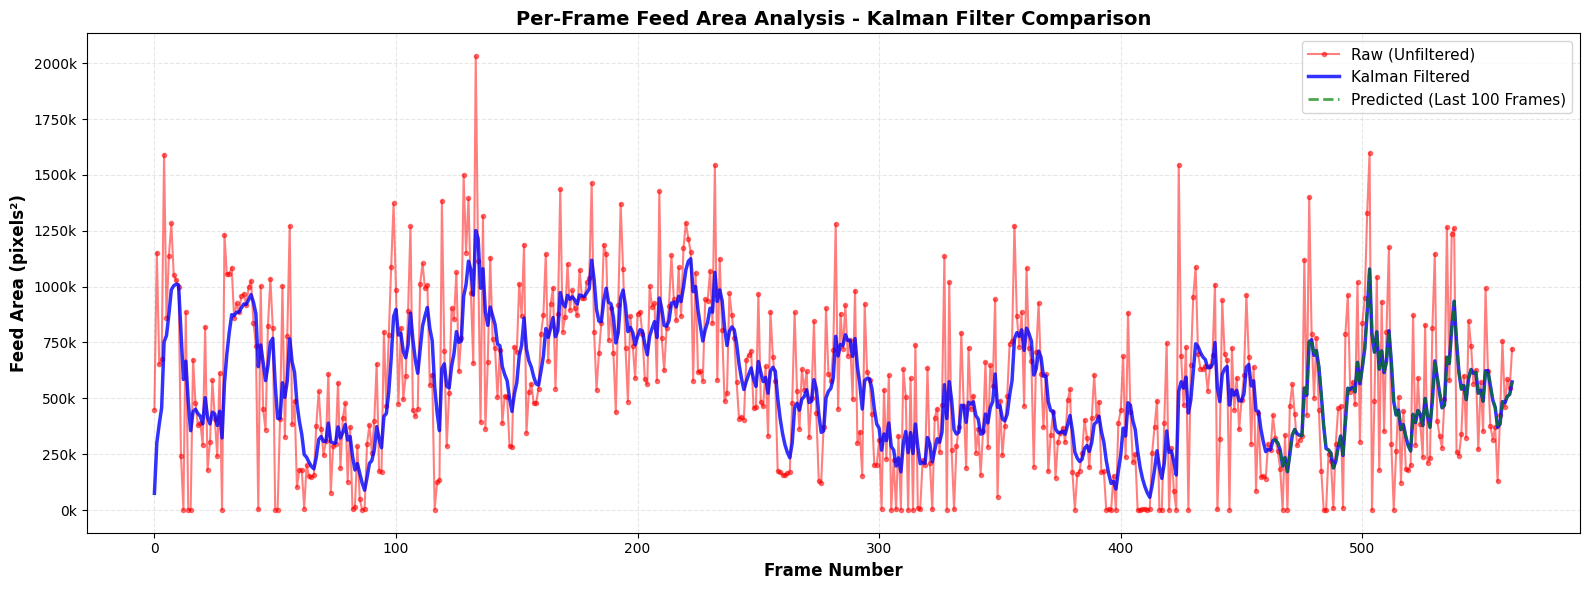

Chart saved as 'feed_amount_analysis.png'


In [8]:
fig, ax = plt.subplots(figsize=(16, 6))

# 繪製原始值
ax.plot(frame_numbers, feed_areas_raw, 
        label='Raw (Unfiltered)', 
        color='red', 
        alpha=0.5, 
        linewidth=1.5,
        marker='o',
        markersize=3)

# 繪製濾波值
ax.plot(frame_numbers, feed_areas_filtered, 
        label='Kalman Filtered', 
        color='blue', 
        linewidth=2.5,
        alpha=0.8)

# 繪製預測值（僅顯示後半部分以避免圖表混亂）
if len(predictions) > 100:
    ax.plot(frame_numbers[-100:], predictions[-100:], 
            label='Predicted (Last 100 Frames)', 
            color='green', 
            linewidth=2,
            linestyle='--',
            alpha=0.7)

ax.set_xlabel('Frame Number', fontsize=12, fontweight='bold')
ax.set_ylabel('Feed Area (pixels²)', fontsize=12, fontweight='bold')
ax.set_title('Per-Frame Feed Area Analysis - Kalman Filter Comparison', fontsize=14, fontweight='bold')
ax.legend(fontsize=11, loc='upper right')
ax.grid(True, alpha=0.3, linestyle='--')

# 設置 y 軸為千位分隔符
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{int(x/1000)}k'))

plt.tight_layout()
plt.savefig('feed_amount_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

print("Chart saved as 'feed_amount_analysis.png'")

## 7. Detailed Analysis - Error Display

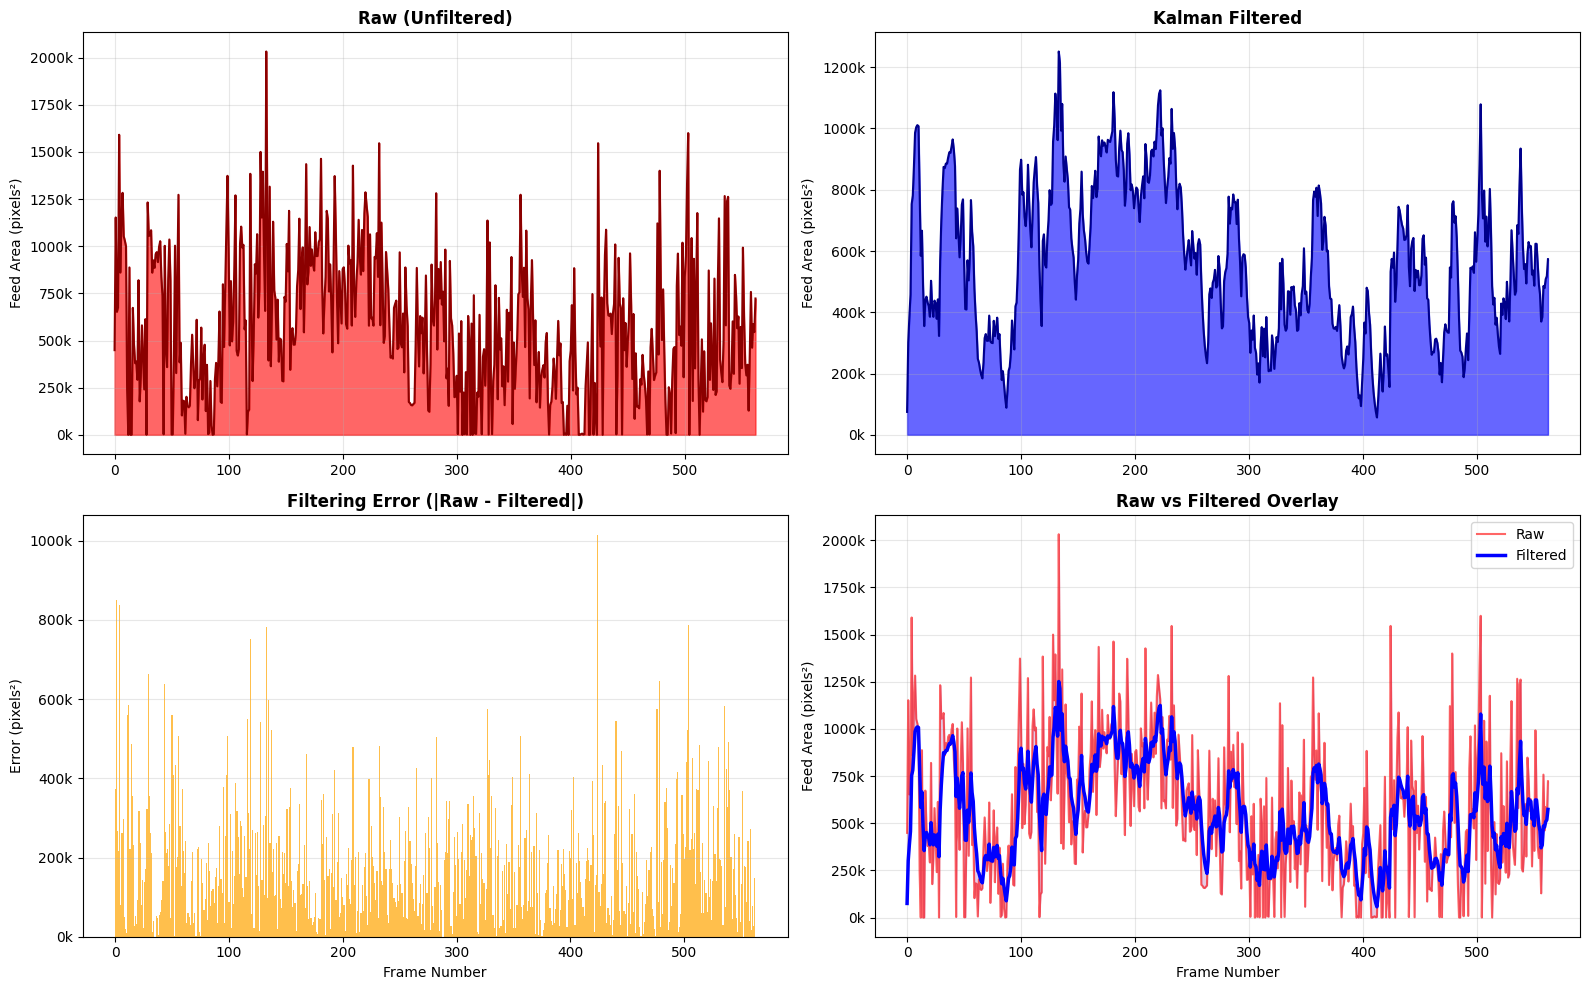

Detailed analysis chart saved as 'feed_amount_detailed_analysis.png'


In [9]:
# 計算誤差（原始值與濾波值的差異）
errors = np.abs(feed_areas_raw - feed_areas_filtered)

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 子圖1: 原始值
axes[0, 0].fill_between(frame_numbers, feed_areas_raw, alpha=0.6, color='red')
axes[0, 0].plot(frame_numbers, feed_areas_raw, color='darkred', linewidth=1.5)
axes[0, 0].set_title('Raw (Unfiltered)', fontsize=12, fontweight='bold')
axes[0, 0].set_ylabel('Feed Area (pixels²)', fontsize=10)
axes[0, 0].grid(True, alpha=0.3)
axes[0, 0].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{int(x/1000)}k'))

# 子圖2: 濾波值
axes[0, 1].fill_between(frame_numbers, feed_areas_filtered, alpha=0.6, color='blue')
axes[0, 1].plot(frame_numbers, feed_areas_filtered, color='darkblue', linewidth=1.5)
axes[0, 1].set_title('Kalman Filtered', fontsize=12, fontweight='bold')
axes[0, 1].set_ylabel('Feed Area (pixels²)', fontsize=10)
axes[0, 1].grid(True, alpha=0.3)
axes[0, 1].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{int(x/1000)}k'))

# 子圖3: 誤差
axes[1, 0].bar(frame_numbers, errors, color='orange', alpha=0.7, width=1)
axes[1, 0].set_title('Filtering Error (|Raw - Filtered|)', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Frame Number', fontsize=10)
axes[1, 0].set_ylabel('Error (pixels²)', fontsize=10)
axes[1, 0].grid(True, alpha=0.3, axis='y')
axes[1, 0].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{int(x/1000)}k'))

# 子圖4: 對比疊加
axes[1, 1].plot(frame_numbers, feed_areas_raw, label='Raw', color='red', alpha=0.6, linewidth=1.5)
axes[1, 1].plot(frame_numbers, feed_areas_filtered, label='Filtered', color='blue', linewidth=2.5)
axes[1, 1].fill_between(frame_numbers, feed_areas_raw, feed_areas_filtered, alpha=0.2, color='purple')
axes[1, 1].set_title('Raw vs Filtered Overlay', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Frame Number', fontsize=10)
axes[1, 1].set_ylabel('Feed Area (pixels²)', fontsize=10)
axes[1, 1].legend(fontsize=10)
axes[1, 1].grid(True, alpha=0.3)
axes[1, 1].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{int(x/1000)}k'))

plt.tight_layout()
plt.savefig('feed_amount_detailed_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

print("Detailed analysis chart saved as 'feed_amount_detailed_analysis.png'")

## 8. Prediction Performance Analysis

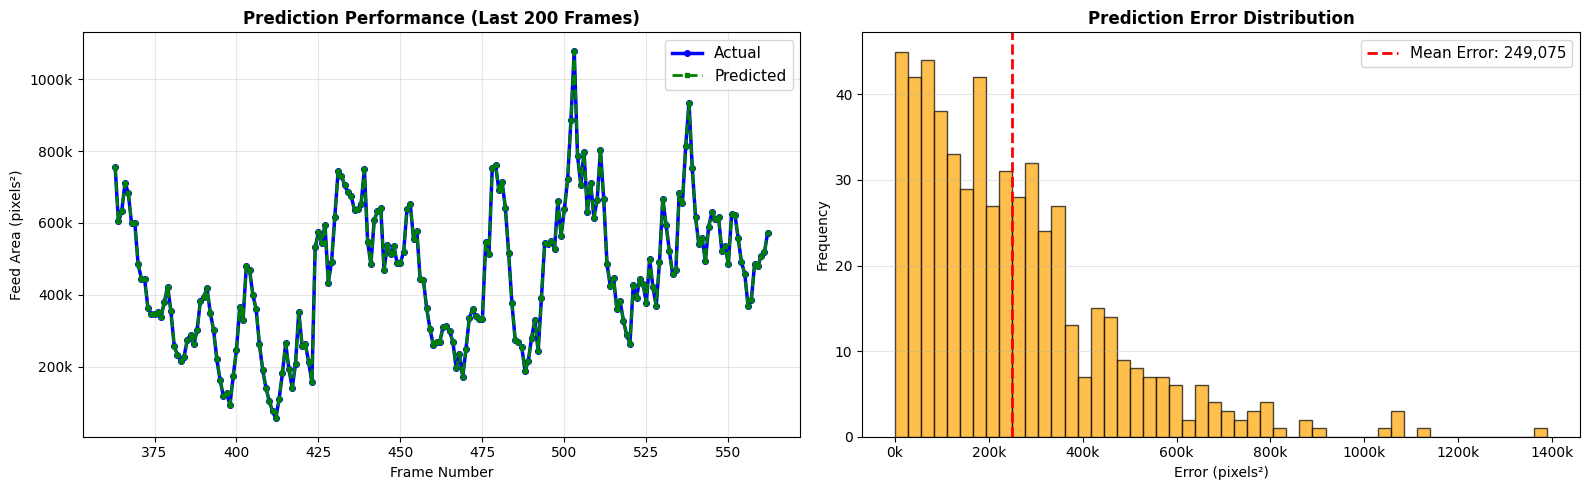

Prediction analysis chart saved as 'feed_amount_prediction_analysis.png'


In [10]:
# 計算預測誤差
prediction_errors = np.abs(predictions[:-1] - feed_areas_raw[1:])

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 左圖: 預測值 vs 實際值 (最後200幀)
n_recent = min(200, len(frame_numbers))
recent_frames = frame_numbers[-n_recent:]
recent_actual = feed_areas_filtered[-n_recent:]
recent_pred = predictions[-n_recent:]

axes[0].plot(recent_frames, recent_actual, label='Actual', color='blue', linewidth=2.5, marker='o', markersize=4)
axes[0].plot(recent_frames, recent_pred, label='Predicted', color='green', linewidth=2, marker='s', markersize=3, linestyle='--')
axes[0].fill_between(recent_frames, recent_actual, recent_pred, alpha=0.2, color='purple')
axes[0].set_title(f'Prediction Performance (Last {n_recent} Frames)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Frame Number', fontsize=10)
axes[0].set_ylabel('Feed Area (pixels²)', fontsize=10)
axes[0].legend(fontsize=11)
axes[0].grid(True, alpha=0.3)
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{int(x/1000)}k'))

# 右圖: 預測誤差分佈
axes[1].hist(prediction_errors, bins=50, color='orange', alpha=0.7, edgecolor='black')
axes[1].axvline(prediction_errors.mean(), color='red', linestyle='--', linewidth=2, label=f'Mean Error: {prediction_errors.mean():,.0f}')
axes[1].set_title('Prediction Error Distribution', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Error (pixels²)', fontsize=10)
axes[1].set_ylabel('Frequency', fontsize=10)
axes[1].legend(fontsize=11)
axes[1].grid(True, alpha=0.3, axis='y')
axes[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{int(x/1000)}k'))

plt.tight_layout()
plt.savefig('feed_amount_prediction_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

print("Prediction analysis chart saved as 'feed_amount_prediction_analysis.png'")

## 9. Prediction Statistics

In [11]:
print("=" * 60)
print("Kalman Filter 預測性能")
print("=" * 60)

print(f"\n預測誤差統計 (1-step ahead):")
print(f"  平均誤差 (MAE): {prediction_errors.mean():,.0f} pixels²")
print(f"  最大誤差: {prediction_errors.max():,.0f} pixels²")
print(f"  最小誤差: {prediction_errors.min():,.0f} pixels²")
print(f"  標準差: {prediction_errors.std():,.0f} pixels²")

# 計算 MAPE (Mean Absolute Percentage Error)
mape = np.mean(np.abs((feed_areas_raw[1:] - predictions[:-1]) / (feed_areas_raw[1:] + 1e-5))) * 100
print(f"  MAPE: {mape:.2f}%")

Kalman Filter 預測性能

預測誤差統計 (1-step ahead):
  平均誤差 (MAE): 249,075 pixels²
  最大誤差: 1,389,592 pixels²
  最小誤差: 92 pixels²
  標準差: 207,535 pixels²
  MAPE: 88282634073.84%


## 10. Tune Kalman Filter Parameters (Optional)

In [12]:
def test_kalman_parameters(q_values, r_values):
    """
    測試不同的 Kalman Filter 參數組合
    
    Args:
        q_values: 過程噪聲方差列表
        r_values: 測量噪聲方差列表
    """
    results = []
    
    for q in q_values:
        for r in r_values:
            kf_test = KalmanFilterND(process_variance=q, measurement_variance=r)
            filtered = []
            
            for measurement in feed_areas_raw:
                filtered.append(kf_test.update(measurement))
            
            filtered = np.array(filtered)
            mae = np.mean(np.abs(feed_areas_raw - filtered))
            rmse = np.sqrt(np.mean((feed_areas_raw - filtered) ** 2))
            
            results.append({
                'q': q,
                'r': r,
                'mae': mae,
                'rmse': rmse,
                'filtered': filtered
            })
    
    return results

# 測試不同參數
print("測試不同的 Kalman Filter 參數...")
q_values = [0.5, 1.0, 2.0, 5.0]
r_values = [5.0, 10.0, 20.0, 50.0]

results = test_kalman_parameters(q_values, r_values)

print("\n參數對比結果 (按 MAE 排序):")
print(f"{'Q (過程噪聲)':>15} {'R (測量噪聲)':>20} {'MAE':>15} {'RMSE':>15}")
print("=" * 65)

sorted_results = sorted(results, key=lambda x: x['mae'])
for i, result in enumerate(sorted_results[:5]):
    print(f"{result['q']:>15.1f} {result['r']:>20.1f} {result['mae']:>15,.0f} {result['rmse']:>15,.0f}")

測試不同的 Kalman Filter 參數...

參數對比結果 (按 MAE 排序):
       Q (過程噪聲)             R (測量噪聲)             MAE            RMSE
            5.0                  5.0          99,788         131,128
            5.0                 10.0         127,376         167,073
            2.0                  5.0         135,843         177,863
            5.0                 20.0         152,969         200,254
            1.0                  5.0         160,201         209,311


## 11. Export Result Data

In [13]:
import pandas as pd

# 創建結果 DataFrame
results_df = pd.DataFrame({
    'Frame': frame_numbers,
    'Raw_Feed_Area': feed_areas_raw,
    'Filtered_Feed_Area': feed_areas_filtered,
    'Predicted_Feed_Area': predictions,
    'Filtering_Error': np.abs(feed_areas_raw - feed_areas_filtered),
})

# 保存為 CSV
csv_path = 'feed_amount_analysis_results.csv'
results_df.to_csv(csv_path, index=False)
print(f"結果已保存為 '{csv_path}'")

# 顯示前幾行
print("\n數據預覽 (前10行):")
print(results_df.head(10))

# 顯示統計摘要
print("\n\n統計摘要:")
print(results_df.describe())

結果已保存為 'feed_amount_analysis_results.csv'

數據預覽 (前10行):
   Frame  Raw_Feed_Area  Filtered_Feed_Area  Predicted_Feed_Area  \
0      0   4.489948e+05        7.483246e+04         7.483246e+04   
1      1   1.152444e+06        3.016981e+05         3.016981e+05   
2      2   6.525191e+05        3.848243e+05         3.848243e+05   
3      3   6.742065e+05        4.577566e+05         4.577566e+05   
4      4   1.590886e+06        7.527897e+05         7.527897e+05   
5      5   8.604231e+05        7.813024e+05         7.813024e+05   
6      6   1.139091e+06        8.769567e+05         8.769567e+05   
7      7   1.283061e+06        9.860596e+05         9.860596e+05   
8      8   1.053107e+06        1.004119e+06         1.004119e+06   
9      9   1.029251e+06        1.010898e+06         1.010898e+06   

   Filtering_Error  
0    374162.289062  
1    850746.062500  
2    267694.781250  
3    216449.875000  
4    838096.312500  
5     79120.625000  
6    262133.937500  
7    297001.000000  
8     

## 12. Advanced Analysis - Trend Detection

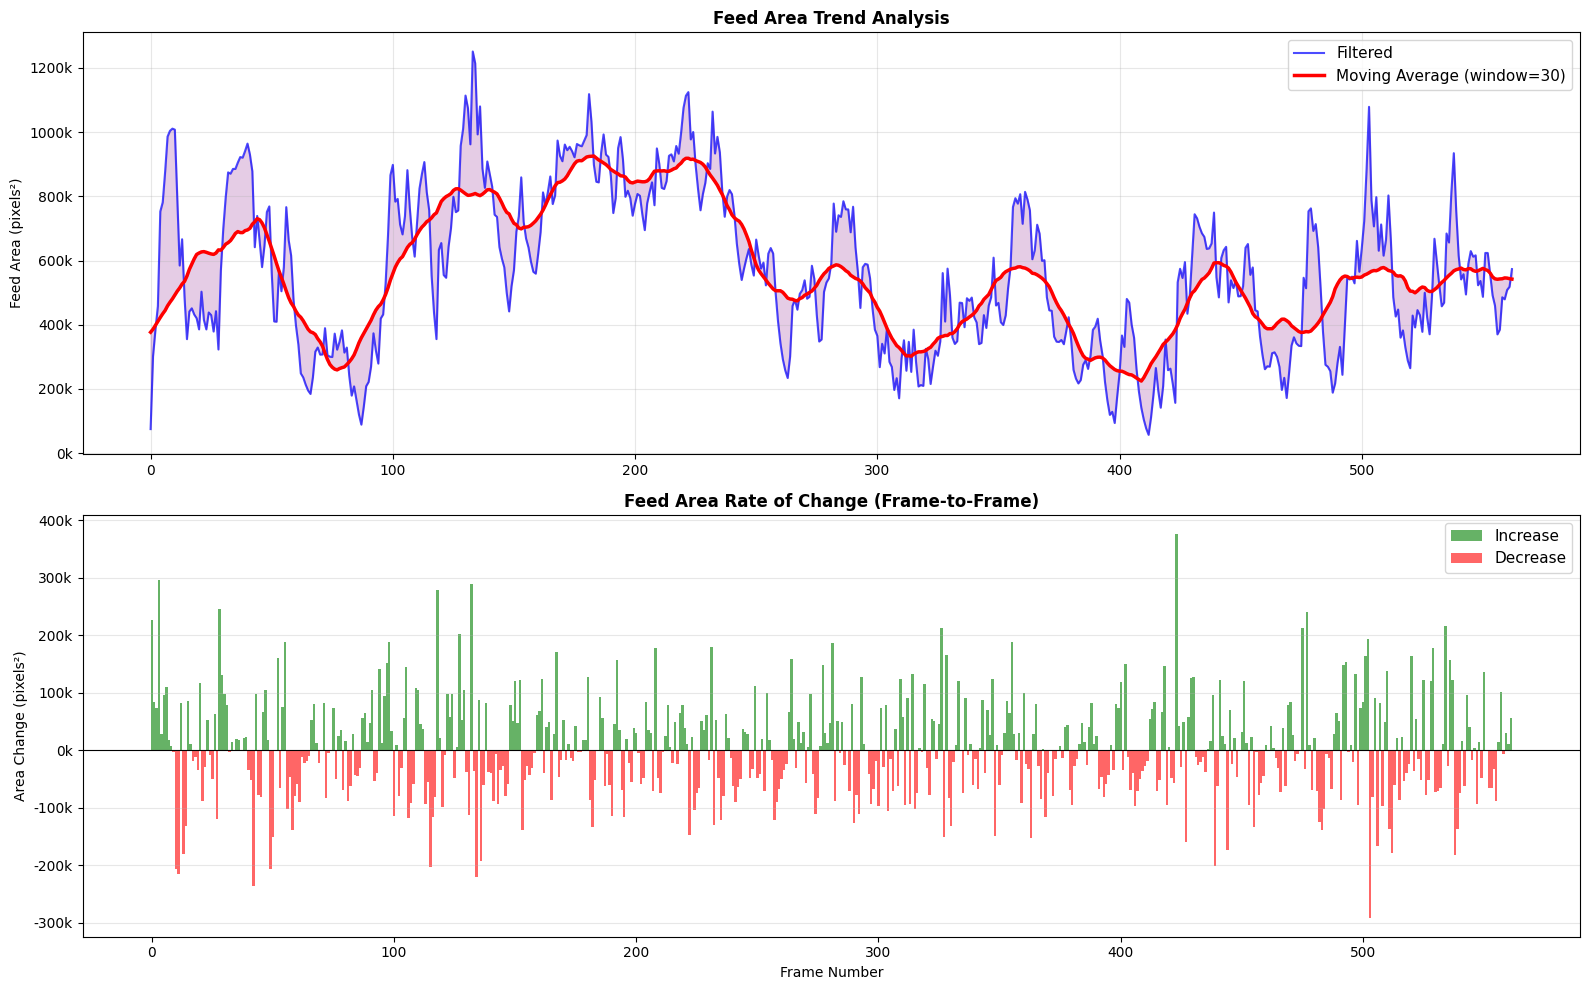

Trend analysis chart saved as 'feed_amount_trend_analysis.png'


In [14]:
# 計算移動平均線 (用於趨勢分析)
window_size = 30
ma_filtered = uniform_filter1d(feed_areas_filtered, size=window_size, mode='nearest')

# 計算速率變化 (一階導數)
rate_of_change = np.diff(feed_areas_filtered)

fig, axes = plt.subplots(2, 1, figsize=(16, 10))

# 上圖: 趨勢分析
axes[0].plot(frame_numbers, feed_areas_filtered, label='Filtered', color='blue', linewidth=1.5, alpha=0.7)
axes[0].plot(frame_numbers, ma_filtered, label=f'Moving Average (window={window_size})', color='red', linewidth=2.5)
axes[0].fill_between(frame_numbers, feed_areas_filtered, ma_filtered, alpha=0.2, color='purple')
axes[0].set_title('Feed Area Trend Analysis', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Feed Area (pixels²)', fontsize=10)
axes[0].legend(fontsize=11)
axes[0].grid(True, alpha=0.3)
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{int(x/1000)}k'))

# 下圖: 速率變化
colors = ['green' if x > 0 else 'red' for x in rate_of_change]
axes[1].bar(frame_numbers[:-1], rate_of_change, color=colors, alpha=0.6, width=1)
axes[1].axhline(y=0, color='black', linestyle='-', linewidth=0.8)
axes[1].set_title('Feed Area Rate of Change (Frame-to-Frame)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Frame Number', fontsize=10)
axes[1].set_ylabel('Area Change (pixels²)', fontsize=10)
axes[1].grid(True, alpha=0.3, axis='y')
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{int(x/1000)}k'))

# 添加圖例
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor='green', alpha=0.6, label='Increase'),
                   Patch(facecolor='red', alpha=0.6, label='Decrease')]
axes[1].legend(handles=legend_elements, fontsize=11, loc='upper right')

plt.tight_layout()
plt.savefig('feed_amount_trend_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

print("Trend analysis chart saved as 'feed_amount_trend_analysis.png'")

## 13. Summary Report

In [15]:
print("\n" + "=" * 70)
print(" " * 20 + "飼料量分析 - 完整報告")
print("=" * 70)

print(f"\n【基本信息】")
print(f"  視頻文件: {CONFIG['video_path']}")
print(f"  YOLO 模型: {CONFIG['model_path']}")
print(f"  處理幀數: {len(frame_numbers)}")
print(f"  視頻時長: {len(frame_numbers)/fps:.2f} 秒")
print(f"  信心度閾值: {CONFIG['confidence_threshold']}")

print(f"\n【飼料面積統計】")
print(f"  原始值範圍: {feed_areas_raw.min():,.0f} ~ {feed_areas_raw.max():,.0f} pixels²")
print(f"  濾波值範圍: {feed_areas_filtered.min():,.0f} ~ {feed_areas_filtered.max():,.0f} pixels²")
print(f"  原始平均值: {feed_areas_raw.mean():,.0f} pixels²")
print(f"  濾波平均值: {feed_areas_filtered.mean():,.0f} pixels²")

print(f"\n【Kalman Filter 參數】")
print(f"  過程噪聲 (Q): {CONFIG['kalman_q']}")
print(f"  測量噪聲 (R): {CONFIG['kalman_r']}")
print(f"  降噪效率: {noise_reduction:.1f}%")

print(f"\n【預測性能】")
print(f"  平均絕對誤差 (MAE): {prediction_errors.mean():,.0f} pixels²")
print(f"  平均百分比誤差 (MAPE): {mape:.2f}%")
print(f"  均方根誤差 (RMSE): {np.sqrt(np.mean(prediction_errors**2)):,.0f} pixels²")

print(f"\n【輸出文件】")
print(f"  ✓ feed_amount_analysis.png - 主要對比圖")
print(f"  ✓ feed_amount_detailed_analysis.png - 詳細分析圖")
print(f"  ✓ feed_amount_prediction_analysis.png - 預測性能圖")
print(f"  ✓ feed_amount_trend_analysis.png - 趨勢分析圖")
print(f"  ✓ feed_amount_analysis_results.csv - 數據導出")

print("\n" + "=" * 70)
print("分析完成！")
print("=" * 70)


                    飼料量分析 - 完整報告

【基本信息】
  視頻文件: data/fish_feeding.mp4
  YOLO 模型: runs/train/fold-4_20260517_1930/weights/best.pt
  處理幀數: 563
  視頻時長: 18.77 秒
  信心度閾值: 0.4

【飼料面積統計】
  原始值範圍: 0 ~ 2,032,343 pixels²
  濾波值範圍: 56,931 ~ 1,251,195 pixels²
  原始平均值: 567,510 pixels²
  濾波平均值: 563,833 pixels²

【Kalman Filter 參數】
  過程噪聲 (Q): 1.0
  測量噪聲 (R): 10.0
  降噪效率: 33.4%

【預測性能】
  平均絕對誤差 (MAE): 249,075 pixels²
  平均百分比誤差 (MAPE): 88282634073.84%
  均方根誤差 (RMSE): 324,205 pixels²

【輸出文件】
  ✓ feed_amount_analysis.png - 主要對比圖
  ✓ feed_amount_detailed_analysis.png - 詳細分析圖
  ✓ feed_amount_prediction_analysis.png - 預測性能圖
  ✓ feed_amount_trend_analysis.png - 趨勢分析圖
  ✓ feed_amount_analysis_results.csv - 數據導出

分析完成！
